# 1. One issue: the price of the kWh

**Examples of:**

- a negotiation on **one issue**, the price, between two agents (as in the carpool book);
- the **zone of possible agreement** (ZOPA) and the Nash price;
- why a negotiation on the price alone can miss an agreement that would be better for **both**.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from charging import *

## 1.1 The situation

Alice owns a house with a **22 kW wallbox** in her yard. She works during the day and mostly uses her electric car at the weekend.  
Bob, her neighbour, is a **home nurse**: he chains short visits in the district and often comes home between two visits.  
He has just bought an electric car. He has not the possibility to install a charger.  
Bob asks Alice to share her charger. First, they only talk about the **price of the kWh**.

| | Alice (owner) | Bob (user) |
|---|---|---|
| first offer | asks **0.40 EUR/kWh** (`ALICE_START`) | offers **0.16 EUR/kWh** (`BOB_START`) |
| limit | never less than **0.20 EUR/kWh**: what the kWh costs her (`ALICE_COST`) | never more than **0.35 EUR/kWh**: the public charger of the district (`PUBLIC_PRICE`) |
| gain per kWh at price $p$ | $p - 0.20$ | $0.35 - p$ |
| if no deal | she keeps her charger for herself: gain 0 | he uses the public charger: gain 0 |

Bob drives about 1200 km per month: he needs about **200 kWh per month** (`KWH_PER_MONTH`).

*Orders of magnitude (2026): regulated tariff about 0.20 EUR/kWh (base option), 0.16 EUR/kWh in off-peak hours.  
Public chargers are more expensive. The 0.35 EUR/kWh of the public charger is an assumption of the scenario.*

`price_gains(price)` returns the gains of Alice and Bob per kWh:

In [3]:
for price in (0.20, 0.30, 0.35):
    print(f"price {price:.2f} EUR/kWh -> gains per kWh (Alice, Bob) = {np.round(price_gains(price), 3)}")

price 0.20 EUR/kWh -> gains per kWh (Alice, Bob) = [0.   0.15]
price 0.30 EUR/kWh -> gains per kWh (Alice, Bob) = [0.1  0.05]
price 0.35 EUR/kWh -> gains per kWh (Alice, Bob) = [0.15 0.  ]


---

**Exercise 1**.
- Which prices are acceptable for **both** Alice and Bob? This interval is the **ZOPA** (*zone of possible agreement*).
- The Nash price maximises the product of the gains over the disagreement point (no deal: gains 0):
$\max_p\ (p - 0.20)(0.35 - p)$.  
- Find either : 
  - on a grid of prices (e.g. `np.linspace(0.20, 0.35, 151)`).
  - via the roots of $derivative((p - 0.20)(0.35 - p))$ 
  `np.roots([-1, .15, -0.07])`
- How is the surplus shared at this price?
- At this price, how much does each one gain **per month** (200 kWh)?

In [15]:
# Exercise 1: your code here
#with derivative : 
import sympy as sp
p = sp.symbols('p')
f_nash = (p - 0.20)*(0.35 - p) 
derivative = sp.diff(f_nash, p)
p_max = sp.solve(derivative, p)[0]
print(f"max of {f_nash} when p={p_max:.3f}")
#with linspace.....

max of (0.35 - p)*(p - 0.2) when p=0.275


In [ ]:
#TODO

ZOPA: from 0.2 to 0.35 EUR/kWh, surplus 0.15 EUR/kWh
Nash price: 0.275 EUR/kWh, gains per kWh: Alice 0.075, Bob 0.075
per month: Alice earns 15.00 EUR, Bob saves 15.00 EUR


> **Reading.**
> - Any price between 0.20 and 0.35 EUR/kWh is better than no deal for both: the surplus is 0.15 EUR per kWh.
> - The product $(p - 0.20)(0.35 - p)$ is maximal at **0.275 EUR/kWh**, the middle of the ZOPA:
> each one gains 0.075 EUR per kWh, i.e. 15 EUR per month.
> - The equal split is a **consequence** of the argmax, not its definition: here the gains are linear in the price
> (one euro more for Alice is one euro less for Bob), and the product of two numbers with a fixed sum is maximal when they are equal.
> With non-linear utilities (e.g. a risk-averse Bob), the Nash solution is **not** an equal split of the money.

---

## 1.2 Two agents negotiate the price

`negotiate_price(alice, bob)` works as in the carpool book: at each round both agents send a price at the same time, 
and there is a deal as soon as the offers cross (the price is the middle of the two offers).  
`time_dependent(r, T, start, limit, beta)` gives the time-dependent offer of the course.

**Exercise 2**.
- Write two **linear** strategies ($\beta = 1$) with `time_dependent`:
  - Alice goes from 0.40 to her limit 0.20,
  - Bob goes from 0.16 to his limit 0.35.
- Run `negotiate_price` and `show_price`. At which price and which round do they agree?

In [5]:
# Exercise 2: your code here

price 0.277 EUR/kWh at round 6 | gains per kWh [0.077 0.073]


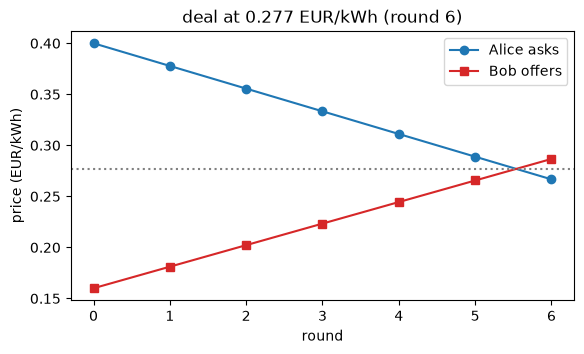

In [17]:
def alice_linear(r, T, mine, theirs):
    return time_dependent(r, T, ALICE_START, ALICE_COST, beta=1)

def bob_linear(r, T, mine, theirs):
    return time_dependent(r, T, BOB_START, PUBLIC_PRICE, beta=1)

result = negotiate_price(alice_linear, bob_linear)
print(f"price {result['price']:.3f} EUR/kWh at round {result['round']} | gains per kWh {np.round(result['gains'], 3)}")
show_price(result);

> **Reading.** 
> - Deal at about **0.277 EUR/kWh**, close to the Nash price: the linear agents split the surplus almost equally.

---

**Exercise 3**.
- Make Alice and Bob negotiate for the pairs Boulware/Conceder, Conceder/Boulware and Boulware/Boulware ($\beta = 0.3$ for Boulware, $3$ for Conceder).
- Print the price and the round of the deal. Who wins?

In [ ]:
# Exercise 3: your code here
def alice(beta):
    #TODO

def bob(beta):
    #TODO

#TODO

Alice beta=0.3, Bob beta=3: price 0.324 EUR/kWh at round 7
Alice beta=3, Bob beta=0.3: price 0.229 EUR/kWh at round 7
Alice beta=0.3, Bob beta=0.3: price 0.277 EUR/kWh at round 8


> **Reading.** 
> - As in the carpool book, the Boulware agent wins: 0.324 EUR/kWh when Alice is Boulware, 0.229 when Bob is.

---

## 1.3 The price is not the only thing

If Bob charges **at night** (22h-7h), Alice pays the off-peak price:  
the kWh costs her only **0.16 EUR** (`ALICE_NIGHT_COST`) instead of 0.20 EUR during the day and the evening.

**Exercise 4**.
- Run the linear negotiation again with a night slot:  
Alice's limit becomes 0.16 EUR/kWh (use the parameter `cost` of `negotiate_price`, and change Alice's limit in her strategy).
- Compare the ZOPA, the price and the gains with a day slot.

In [9]:
# Exercise 4: your code here

In [ ]:
def alice_linear_night(r, T, mine, theirs):
    #TODO

#TODO

ZOPA at night: from 0.16 to 0.35 EUR/kWh
price 0.266 EUR/kWh at round 5
per month: Alice earns 21.22 EUR, Bob saves 16.78 EUR


> **Reading.**
> - At night the ZOPA grows (0.16 to 0.35 EUR/kWh): the agents agree at a **lower** price (about 0.266), and yet
> Alice earns **more** (about 21 EUR per month instead of 15), and Bob saves more (about 17 EUR).
> - The **time slot** changes Alice's cost, hence the price: in book 2, Bob will pay **Alice's tariff of the slot plus a margin**,
> and the agents will negotiate the margin.
> - But money is not everything: Alice works during the day and fears the noise at night; Bob often comes home during the day.
> A negotiation on the price alone cannot take this into account: the agents must negotiate **several issues at once** (book 2).

---

## Key points

| Idea | In the charger sharing |
|---|---|
| ZOPA | from Alice's cost (0.20) to the public charger (0.35 EUR/kWh) |
| Nash price | 0.275 EUR/kWh: 15 EUR per month for each |
| Boulware vs Conceder | the Boulware agent wins, as in the carpool book |
| night slot | Alice's cost falls to 0.16: the price depends on the slot |